# Clasificador de perros y gatos

Notebook del docente adaptado para correr localmente (Anaconda + Jupyter / VS Code).

Cambios respecto al original:
- Celda de configuración con las rutas del proyecto (`modelos/`, `web/modelo/`, `logs/`).
- Los modelos `.h5` se guardan en `modelos/`.
- La conversión a TensorFlow.js usa `src/exportar_tfjs.py` en lugar de `tensorflowjs_converter` (no instala bien en Windows con Python reciente) y escribe directo en `web/modelo/`.

El resto de las celdas es el código del docente sin modificar.

**Tiempo:** las celdas de entrenamiento (100-150 épocas cada una) tardan horas en CPU. La interfaz web ya funciona con el modelo entrenado por el docente; entrenar solo hace falta para reemplazarlo por el tuyo.


In [32]:
%pip install scipy

   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   -- ------------------------------------- 2.4/36.7 MB 14.9 MB/s eta 0:00:03
   --- ------------------------------------ 3.1/36.7 MB 13.2 MB/s eta 0:00:03
   --- ------------------------------------ 3.4/36.7 MB 6.1 MB/s eta 0:00:06
   ---- ----------------------------------- 4.2/36.7 MB 5.2 MB/s eta 0:00:07
   ------- -------------------------------- 6.8/36.7 MB 6.6 MB/s eta 0:00:05
   --------- ------------------------------ 8.4/36.7 MB 6.8 MB/s eta 0:00:05
   ----------- ---------------------------- 10.2/36.7 MB 7.0 MB/s eta 0:00:04
   ------------ --------------------------- 11.5/36.7 MB 7.1 MB/s eta 0:00:04
   -------------- ------------------------- 13.4/36.7 MB 7.2 MB/s eta 0:00:04
   ---------------- ----------------------- 14.9/36.7 MB 7.1 MB/s eta 0:00:04
   ----------------- ---------------------- 16.3/36.7 MB 7.1 MB/s eta 0:00:03
   ------------------- -------------------- 18.1/36.7 MB 7.2 MB/s eta 0:00:0

In [ ]:
%pip install tensorboard


  Using cached tensorboard-2.21.0-py3-none-any.whl.metadata (1.8 kB)
  Using cached markdown-3.11-py3-none-any.whl.metadata (5.1 kB)
  Using cached tensorboard_data_server-0.7.2-py3-none-any.whl.metadata (1.1 kB)
  Using cached werkzeug-3.1.9-py3-none-any.whl.metadata (4.1 kB)
Using cached tensorboard-2.21.0-py3-none-any.whl (5.5 MB)
Using cached tensorboard_data_server-0.7.2-py3-none-any.whl (2.4 kB)
Using cached markdown-3.11-py3-none-any.whl (111 kB)
Using cached werkzeug-3.1.9-py3-none-any.whl (228 kB)

   ---------------------------------------- 0/4 [werkzeug]
   -------------------- ------------------- 2/4 [markdown]
   ------------------------------ --------- 3/4 [tensorboard]
   ------------------------------ --------- 3/4 [tensorboard]
   ------------------------------ --------- 3/4 [tensorboard]
   ------------------------------ --------- 3/4 [tensorboard]
   ------------------------------ --------- 3/4 [tensorboard]
   ------------------------------ --------- 3/4 [tensorboar

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


## 0. Configuración del proyecto

In [1]:
import sys
from pathlib import Path

# Raíz del proyecto (este notebook vive en notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DIR_MODELOS = RAIZ / 'modelos'
DIR_WEB_MODELO = RAIZ / 'web' / 'modelo'
DIR_LOGS = RAIZ / 'logs'
for d in (DIR_MODELOS, DIR_WEB_MODELO, DIR_LOGS):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(RAIZ / 'src'))
print('Raíz del proyecto:', RAIZ)
print('Python:', sys.executable)

Raíz del proyecto: c:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\clasificador-perros-gatos
Python: c:\Users\limber\anaconda3\envs\perrosgatos\python.exe


## 1. Descarga y preparación de datos

In [4]:
import tensorflow as tf
import tensorflow_datasets as tfds

#Correccion temporal (22/mayo/2022)
#Tensorflow datasets tiene error al descargar el set de perros y gatos y lo solucionaron
#el 16 de mayo pero sigue fallando en los colabs. Entonces se agrega esta linea adicional
#Mas detalle aqui: https://github.com/tensorflow/datasets/issues/3918
setattr(tfds.image_classification.cats_vs_dogs, '_URL',"https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip")

# Parche Windows: tfds arma rutas con '\' y zipfile las guarda con '/', así que no encuentra la imagen.
# Forzamos a que ese módulo normalice rutas con '/' (estilo Linux, como en Colab).
import posixpath, types
tfds.image_classification.cats_vs_dogs.os = types.SimpleNamespace(
    path=types.SimpleNamespace(normpath=lambda p: posixpath.normpath(p.replace('\\', '/'))))

#Descargar el set de datos de perros y gatos
datos, metadatos = tfds.load('cats_vs_dogs', as_supervised=True, with_info=True)

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]WARNING:absl:1738 images were corrupted and were skipped
                                                                        

Dataset cats_vs_dogs downloaded and prepared to C:\Users\limber\tensorflow_datasets\cats_vs_dogs\4.0.1. Subsequent calls will reuse this data.


In [5]:
#Imprimir los metadatos para revisarlos
metadatos

tfds.core.DatasetInfo(
    name='cats_vs_dogs',
    full_name='cats_vs_dogs/4.0.1',
    description="""
    A large set of images of cats and dogs. There are 1738 corrupted images that are dropped.
    """,
    homepage='https://www.microsoft.com/en-us/download/details.aspx?id=54765',
    data_dir='C:\\Users\\limber\\tensorflow_datasets\\cats_vs_dogs\\4.0.1',
    file_format=tfrecord,
    download_size=786.67 MiB,
    dataset_size=1.04 GiB,
    features=FeaturesDict({
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'image/filename': Text(shape=(), dtype=string),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=2),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'train': <SplitInfo num_examples=23262, num_shards=16>,
    },
    citation="""@Inproceedings (Conference){asirra-a-captcha-that-exploits-interest-aligned-manual-image-categorization,
    author = {Elson, Jeremy 

,image,label
0,,1 (dog)
1,,1 (dog)
2,,1 (dog)
3,,0 (cat)
4,,1 (dog)

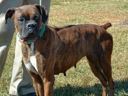
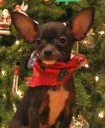
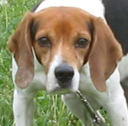
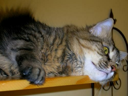
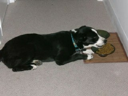

In [6]:
#Una forma de mostrar 5 ejemplos del set
tfds.as_dataframe(datos['train'].take(5), metadatos)

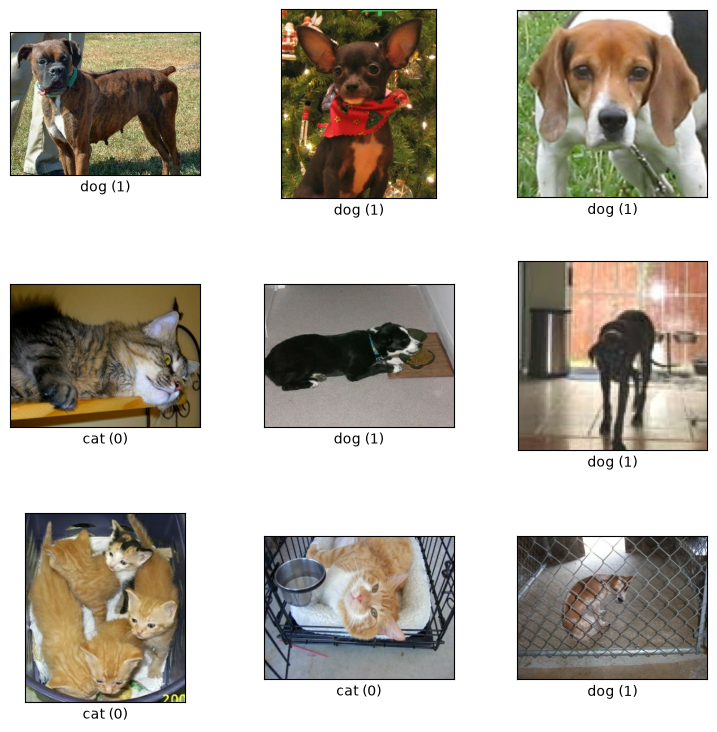

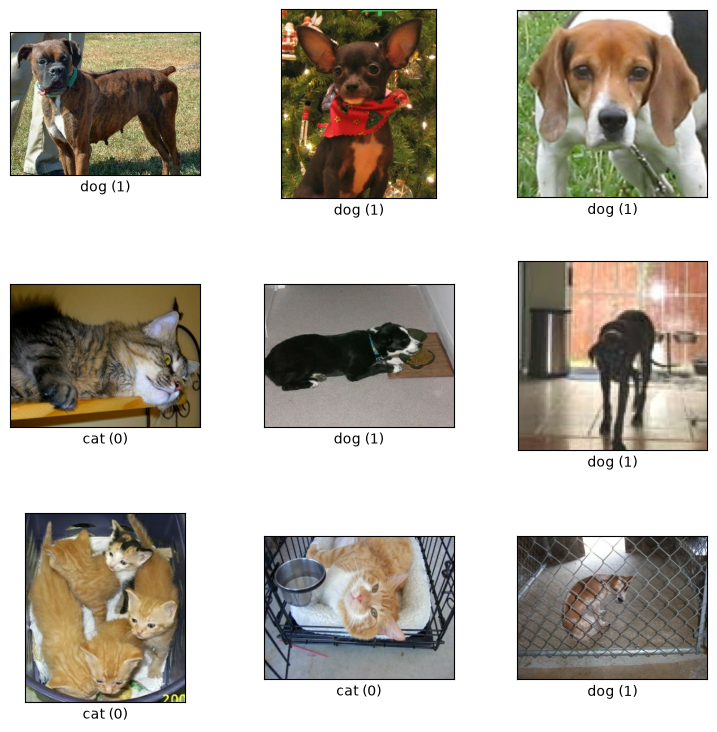

In [7]:
#Otra forma de mostrar ejemplos del set
tfds.show_examples(datos['train'], metadatos)

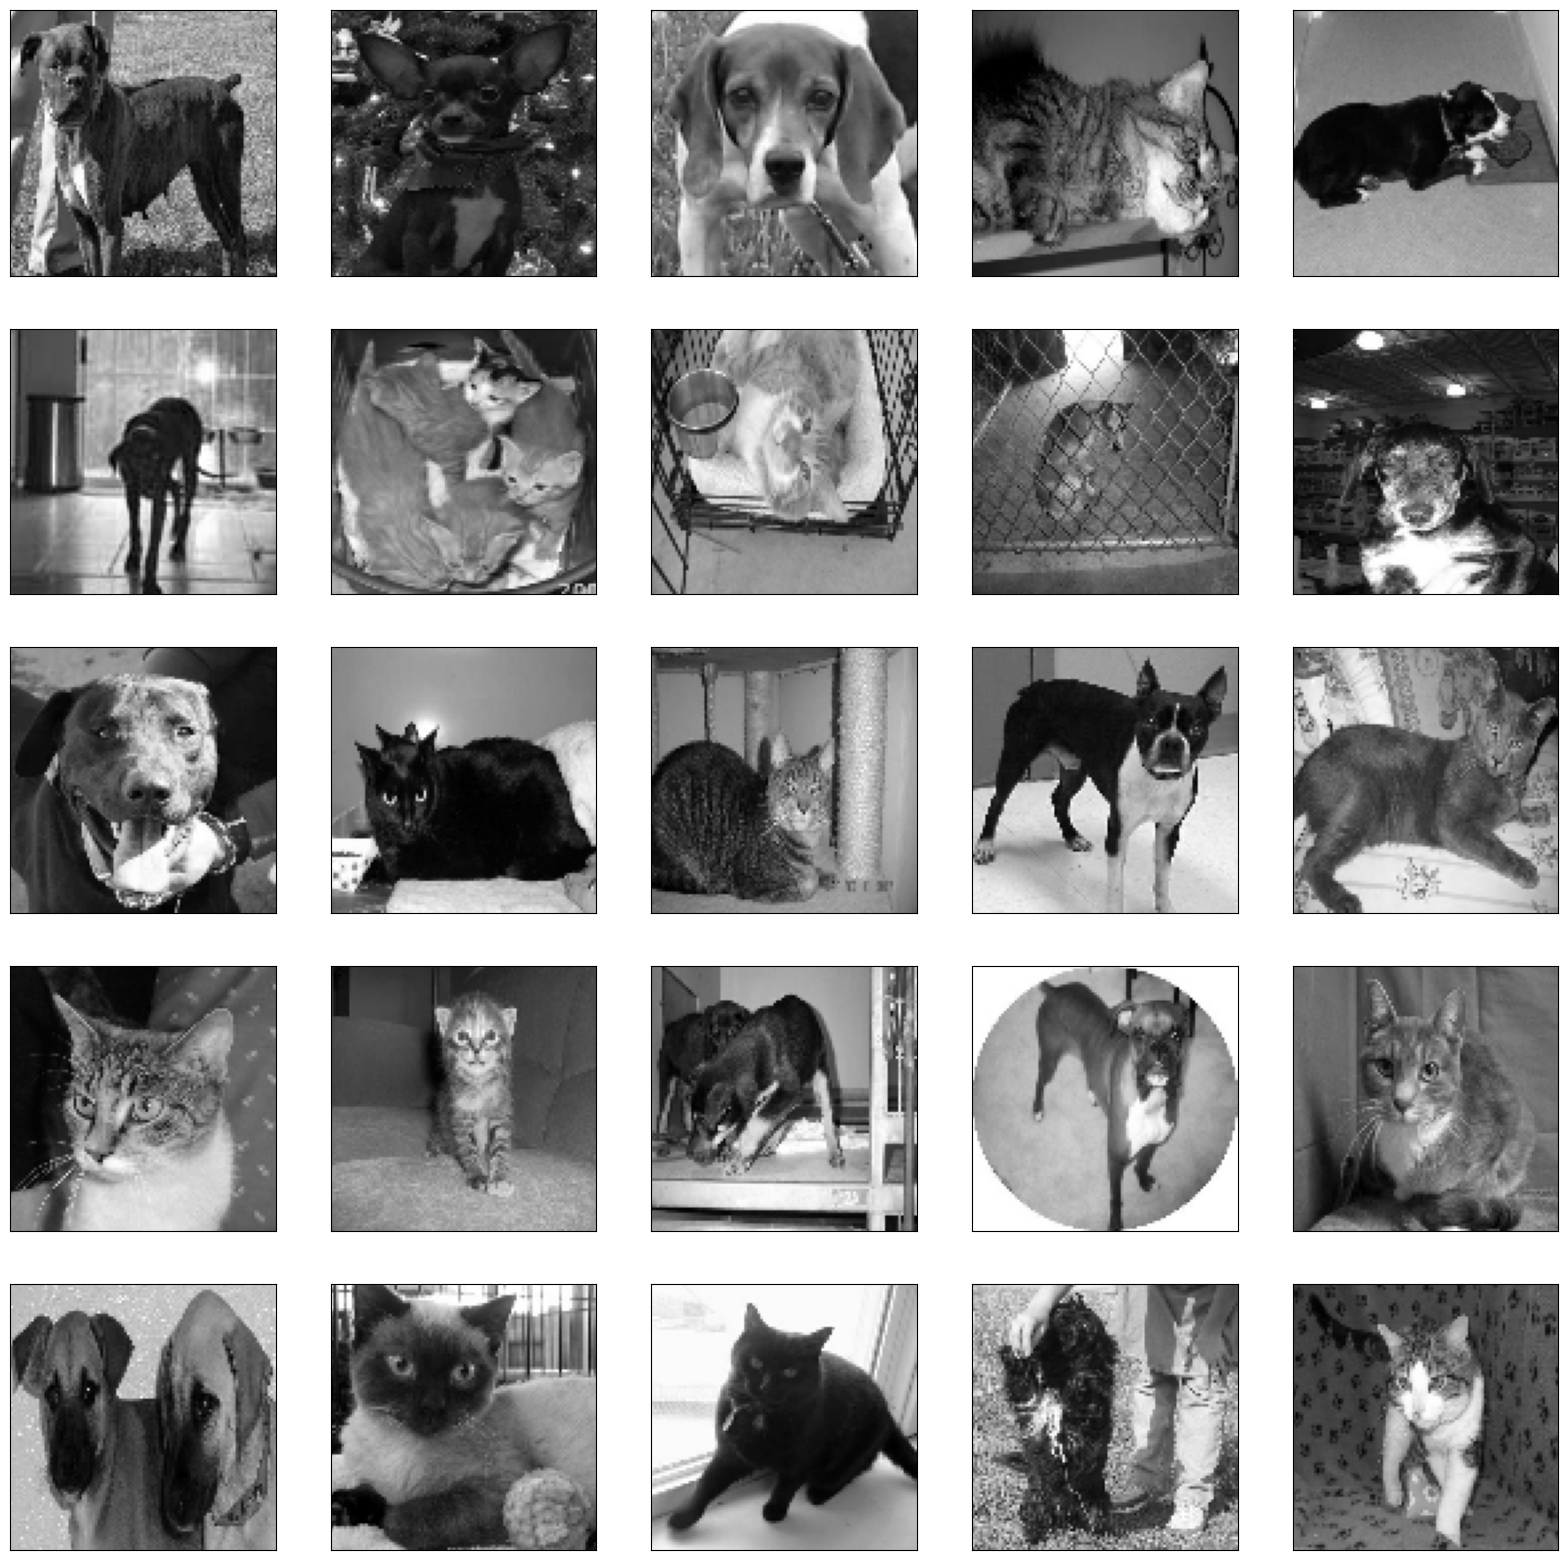

In [8]:
#Manipular y visualizar el set
#Lo pasamos a TAMANO_IMG (100x100) y a blanco y negro (solo para visualizar)
import matplotlib.pyplot as plt
import cv2

plt.figure(figsize=(20,20))

TAMANO_IMG=100

for i, (imagen, etiqueta) in enumerate(datos['train'].take(25)):
  imagen = cv2.resize(imagen.numpy(), (TAMANO_IMG, TAMANO_IMG))
  imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
  plt.subplot(5, 5, i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(imagen, cmap='gray')

In [9]:
#Variable que contendra todos los pares de los datos (imagen y etiqueta) ya modificados (blanco y negro, 100x100)
datos_entrenamiento = []

In [10]:
for i, (imagen, etiqueta) in enumerate(datos['train']): #Todos los datos
  imagen = cv2.resize(imagen.numpy(), (TAMANO_IMG, TAMANO_IMG))
  imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
  imagen = imagen.reshape(TAMANO_IMG, TAMANO_IMG, 1) #Cambiar tamano a 100,100,1
  datos_entrenamiento.append([imagen, etiqueta])

In [11]:
#Ver los datos del primer indice
datos_entrenamiento[0]

[array([[[249],
         [190],
         [105],
         ...,
         [189],
         [196],
         [143]],
 
        [[232],
         [127],
         [ 88],
         ...,
         [187],
         [180],
         [186]],
 
        [[171],
         [ 87],
         [ 83],
         ...,
         [129],
         [158],
         [166]],
 
        ...,
 
        [[113],
         [173],
         [162],
         ...,
         [143],
         [156],
         [119]],
 
        [[140],
         [152],
         [171],
         ...,
         [ 98],
         [155],
         [154]],
 
        [[ 91],
         [109],
         [167],
         ...,
         [ 46],
         [ 51],
         [ 47]]], shape=(100, 100, 1), dtype=uint8),
 <tf.Tensor: shape=(), dtype=int64, numpy=1>]

In [12]:
#Ver cuantos datos tengo en la variable
len(datos_entrenamiento)

23262

In [13]:
#Preparar mis variables X (entradas) y y (etiquetas) separadas

X = [] #imagenes de entrada (pixeles)
y = [] #etiquetas (perro o gato)

for imagen, etiqueta in datos_entrenamiento:
  X.append(imagen)
  y.append(etiqueta)

In [14]:
X

[array([[[249],
         [190],
         [105],
         ...,
         [189],
         [196],
         [143]],
 
        [[232],
         [127],
         [ 88],
         ...,
         [187],
         [180],
         [186]],
 
        [[171],
         [ 87],
         [ 83],
         ...,
         [129],
         [158],
         [166]],
 
        ...,
 
        [[113],
         [173],
         [162],
         ...,
         [143],
         [156],
         [119]],
 
        [[140],
         [152],
         [171],
         ...,
         [ 98],
         [155],
         [154]],
 
        [[ 91],
         [109],
         [167],
         ...,
         [ 46],
         [ 51],
         [ 47]]], shape=(100, 100, 1), dtype=uint8),
 array([[[149],
         [114],
         [ 93],
         ...,
         [103],
         [ 72],
         [ 81]],
 
        [[127],
         [ 63],
         [ 79],
         ...,
         [131],
         [ 70],
         [ 98]],
 
        [[ 82],
         [ 65],
         [ 58],

In [15]:
#Normalizar los datos de las X (imagenes). Se pasan a numero flotante y dividen entre 255 para quedar de 0-1 en lugar de 0-255
import numpy as np

X = np.array(X).astype(float) / 255

In [16]:
y

[<tf.Tensor: shape=(), dtype=int64, numpy=1>,
 <tf.Tensor: shape=(), dtype=int64, numpy=1>,
 <tf.Tensor: shape=(), dtype=int64, numpy=1>,
 <tf.Tensor: shape=(), dtype=int64, numpy=0>,
 <tf.Tensor: shape=(), dtype=int64, numpy=1>,
 <tf.Tensor: shape=(), dtype=int64, numpy=1>,
 <tf.Tensor: shape=(), dtype=int64, numpy=0>,
 <tf.Tensor: shape=(), dtype=int64, numpy=0>,
 <tf.Tensor: shape=(), dtype=int64, numpy=1>,
 <tf.Tensor: shape=(), dtype=int64, numpy=1>,
 <tf.Tensor: shape=(), dtype=int64, numpy=1>,
 <tf.Tensor: shape=(), dtype=int64, numpy=0>,
 <tf.Tensor: shape=(), dtype=int64, numpy=0>,
 <tf.Tensor: shape=(), dtype=int64, numpy=1>,
 <tf.Tensor: shape=(), dtype=int64, numpy=0>,
 <tf.Tensor: shape=(), dtype=int64, numpy=0>,
 <tf.Tensor: shape=(), dtype=int64, numpy=0>,
 <tf.Tensor: shape=(), dtype=int64, numpy=1>,
 <tf.Tensor: shape=(), dtype=int64, numpy=1>,
 <tf.Tensor: shape=(), dtype=int64, numpy=0>,
 <tf.Tensor: shape=(), dtype=int64, numpy=1>,
 <tf.Tensor: shape=(), dtype=int64

In [17]:
#Convertir etiquetas en arreglo simple
y = np.array(y)

In [18]:
X.shape

(23262, 100, 100, 1)

## 2. Modelos sin aumento de datos

In [19]:
#Crear los modelos iniciales
#Usan sigmoid como salida (en lugar de softmax) para mostrar como podria funcionar con dicha funcion de activacion.
#Sigmoid regresa siempre datos entre 0 y 1. Realizamos el entrenamiento para al final considerar que si la respuesta se
#acerca a 0, es un gato, y si se acerca a 1, es un perro.

modeloDenso = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(100, 100, 1)),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(100, 100, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(100, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN2 = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(100, 100, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  tf.keras.layers.Dropout(0.5),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(250, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

c:\Users\limber\anaconda3\envs\perrosgatos\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\limber\anaconda3\envs\perrosgatos\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
#Compilar modelos. Usar crossentropy binario ya que tenemos solo 2 opciones (perro o gato)
modeloDenso.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

modeloCNN.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

modeloCNN2.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

In [21]:
from tensorflow.keras.callbacks import TensorBoard

In [24]:
#La variable de tensorboard se envia en el arreglo de "callbacks" (hay otros tipos de callbacks soportados)
#En este caso guarda datos en la carpeta indicada en cada epoca, de manera que despues
#Tensorboard los lee para hacer graficas
tensorboardDenso = TensorBoard(log_dir=str(DIR_LOGS / 'denso'))
modeloDenso.fit(X, y, batch_size=32,
                validation_split=0.15,
                epochs=100,
                callbacks=[tensorboardDenso])

Epoch 1/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5406 - loss: 0.7151 - val_accuracy: 0.5865 - val_loss: 0.6766
Epoch 2/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.5361 - loss: 0.6863 - val_accuracy: 0.5533 - val_loss: 0.6806
Epoch 3/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.5802 - loss: 0.6734 - val_accuracy: 0.5808 - val_loss: 0.6689
Epoch 4/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.5934 - loss: 0.6661 - val_accuracy: 0.5814 - val_loss: 0.6693
Epoch 5/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.5959 - loss: 0.6649 - val_accuracy: 0.6034 - val_loss: 0.6620
Epoch 6/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.6014 - loss: 0.6637 - val_accuracy: 0.5871 - val_loss: 0.6731
Epoch 7/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6048 - loss: 0.6593 - val_accuracy: 0.5900 - val_loss: 0.6675
Epoch 8/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.6018 - loss: 0.6609 - val

In [25]:
#Cargar la extension de tensorboard de colab
%load_ext tensorboard

In [27]:
#Ejecutar tensorboard e indicarle que lea la carpeta "logs"
import os, sys
from pathlib import Path
# Que %tensorboard use el tensorboard del entorno perrosgatos, no el de Anaconda base
os.environ['TENSORBOARD_BINARY'] = str(Path(sys.executable).parent / 'Scripts' / 'tensorboard.exe')
print(os.environ['TENSORBOARD_BINARY'], Path(os.environ['TENSORBOARD_BINARY']).exists())
%tensorboard --logdir "{DIR_LOGS}"

c:\Users\limber\anaconda3\envs\perrosgatos\Scripts\tensorboard.exe True


In [28]:
tensorboardCNN = TensorBoard(log_dir=str(DIR_LOGS / 'cnn'))
modeloCNN.fit(X, y, batch_size=32,
                validation_split=0.15,
                epochs=100,
                callbacks=[tensorboardCNN])

Epoch 1/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 50s 78ms/step - accuracy: 0.6214 - loss: 0.6353 - val_accuracy: 0.7378 - val_loss: 0.5333
Epoch 2/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 47s 76ms/step - accuracy: 0.7676 - loss: 0.4817 - val_accuracy: 0.7788 - val_loss: 0.4687
Epoch 3/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 47s 76ms/step - accuracy: 0.8130 - loss: 0.4120 - val_accuracy: 0.8192 - val_loss: 0.4058
Epoch 4/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 47s 76ms/step - accuracy: 0.8442 - loss: 0.3510 - val_accuracy: 0.8269 - val_loss: 0.3877
Epoch 5/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 47s 76ms/step - accuracy: 0.8717 - loss: 0.2929 - val_accuracy: 0.8390 - val_loss: 0.3970
Epoch 6/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 48s 77ms/step - accuracy: 0.8978 - loss: 0.2422 - val_accuracy: 0.8421 - val_loss: 0.3741
Epoch 7/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 51s 82ms/step - accuracy: 0.9193 - loss: 0.1953 - val_accuracy: 0.8301 - val_loss: 0.4165
Epoch 8/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 48s 77ms/step - accuracy: 0.9427 - loss: 0

In [29]:
tensorboardCNN2 = TensorBoard(log_dir=str(DIR_LOGS / 'cnn2'))
modeloCNN2.fit(X, y, batch_size=32,
                validation_split=0.15,
                epochs=100,
                callbacks=[tensorboardCNN2])

Epoch 1/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 55s 86ms/step - accuracy: 0.6180 - loss: 0.6405 - val_accuracy: 0.7436 - val_loss: 0.5298
Epoch 2/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 54s 88ms/step - accuracy: 0.7553 - loss: 0.5019 - val_accuracy: 0.7805 - val_loss: 0.4745
Epoch 3/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 51s 82ms/step - accuracy: 0.7936 - loss: 0.4391 - val_accuracy: 0.8223 - val_loss: 0.4039
Epoch 4/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 48s 78ms/step - accuracy: 0.8266 - loss: 0.3826 - val_accuracy: 0.8321 - val_loss: 0.3867
Epoch 5/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 57s 92ms/step - accuracy: 0.8472 - loss: 0.3450 - val_accuracy: 0.8444 - val_loss: 0.3558
Epoch 6/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 54s 87ms/step - accuracy: 0.8670 - loss: 0.3100 - val_accuracy: 0.8513 - val_loss: 0.3375
Epoch 7/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 55s 89ms/step - accuracy: 0.8788 - loss: 0.2813 - val_accuracy: 0.8599 - val_loss: 0.3268
Epoch 8/100
618/618 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.8974 - loss: 0

## 3. Aumento de datos

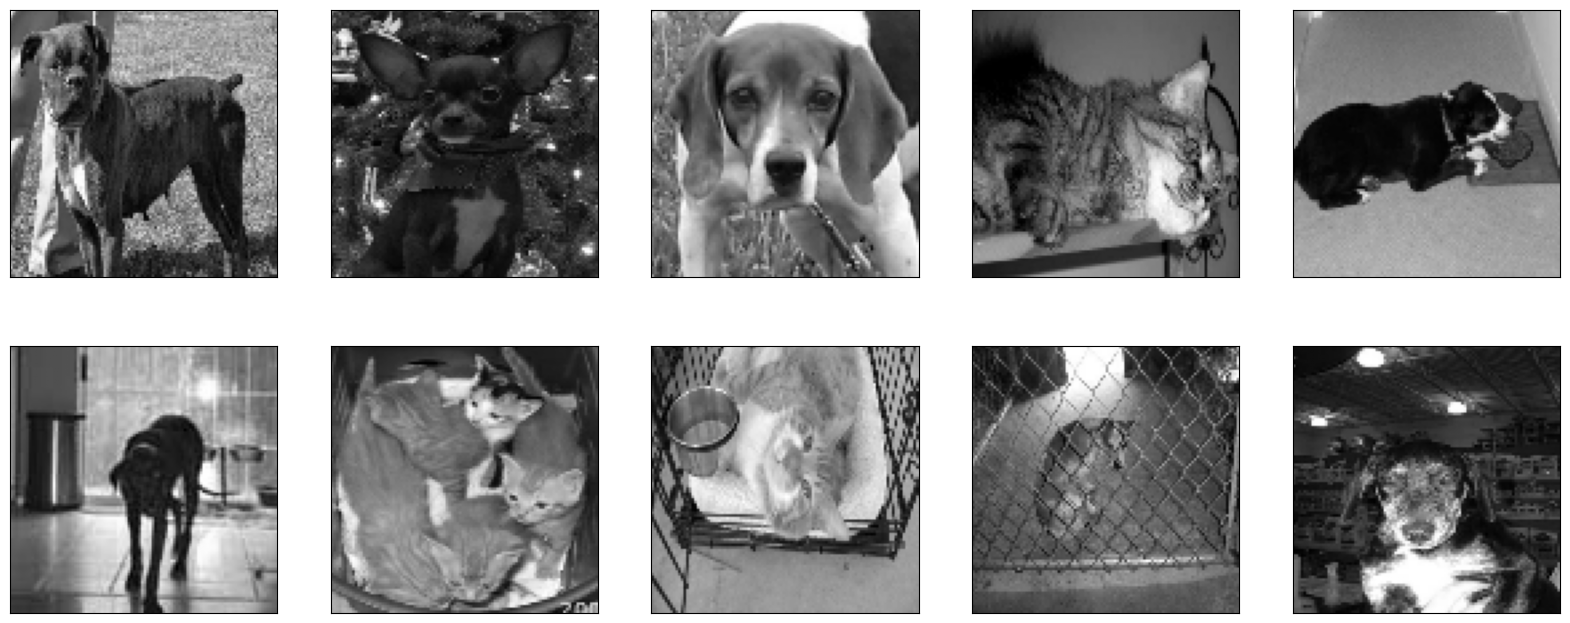

In [33]:
#ver las imagenes de la variable X sin modificaciones por aumento de datos
plt.figure(figsize=(20, 8))
for i in range(10):
  plt.subplot(2, 5, i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(X[i].reshape(100, 100), cmap="gray")

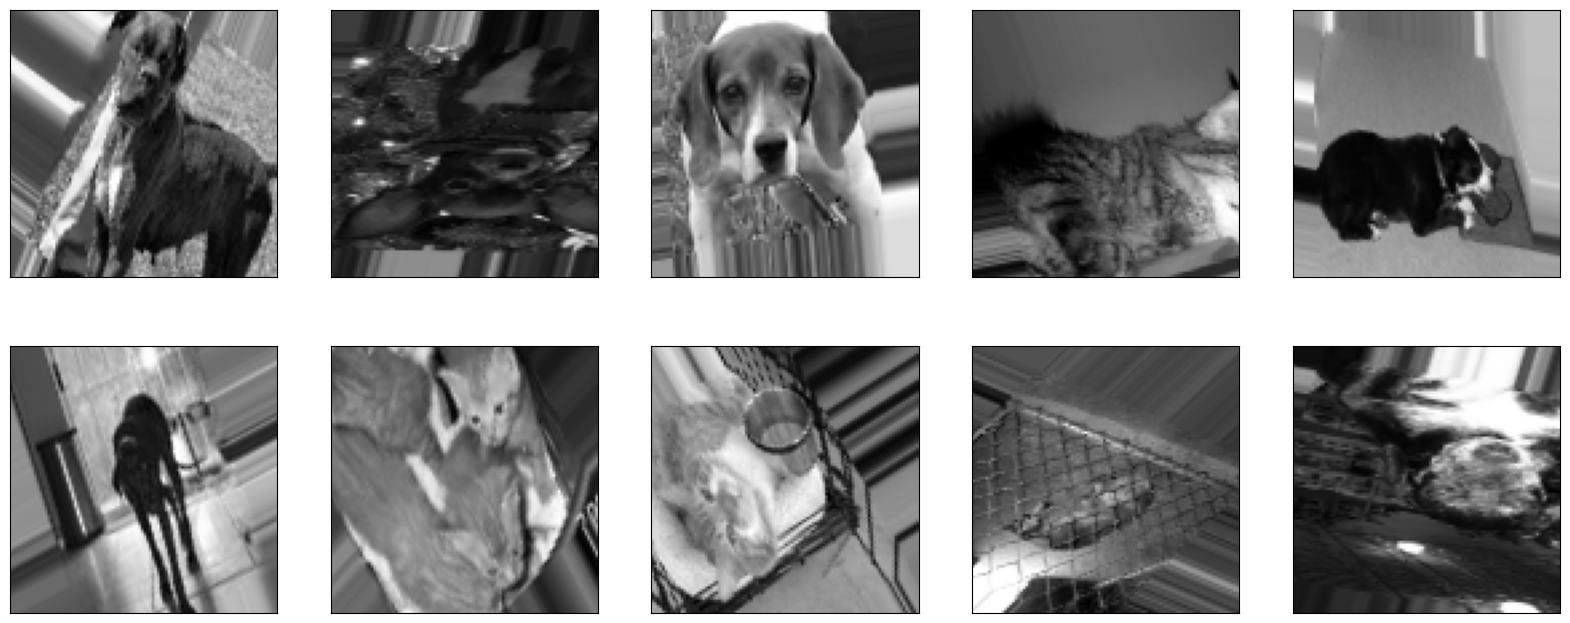

In [34]:
#Realizar el aumento de datos con varias transformaciones. Al final, graficar 10 como ejemplo
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=15,
    zoom_range=[0.7, 1.4],
    horizontal_flip=True,
    vertical_flip=True
)

datagen.fit(X)

plt.figure(figsize=(20,8))

for imagen, etiqueta in datagen.flow(X, y, batch_size=10, shuffle=False):
  for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(imagen[i].reshape(100, 100), cmap="gray")
  break

In [35]:
modeloDenso_AD = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(100, 100, 1)),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN_AD = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(100, 100, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(100, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN2_AD = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(100, 100, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  tf.keras.layers.Dropout(0.5),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(250, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

c:\Users\limber\anaconda3\envs\perrosgatos\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\limber\anaconda3\envs\perrosgatos\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [36]:
modeloDenso_AD.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

modeloCNN_AD.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

modeloCNN2_AD.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

In [37]:
#Separar los datos de entrenamiento y los datos de pruebas en variables diferentes

len(X) * .85 #19700
len(X) - 19700 #3562

X_entrenamiento = X[:19700]
X_validacion = X[19700:]

y_entrenamiento = y[:19700]
y_validacion = y[19700:]

In [38]:
#Usar la funcion flow del generador para crear un iterador que podamos enviar como entrenamiento a la funcion FIT del modelo
data_gen_entrenamiento = datagen.flow(X_entrenamiento, y_entrenamiento, batch_size=32)

In [40]:
tensorboardDenso_AD = TensorBoard(log_dir=str(DIR_LOGS / 'denso_AD'))

modeloDenso_AD.fit(
    data_gen_entrenamiento,
    epochs=100, batch_size=32,
    validation_data=(X_validacion, y_validacion),
    steps_per_epoch=int(np.ceil(len(X_entrenamiento) / float(32))),
    validation_steps=int(np.ceil(len(X_validacion) / float(32))),
    callbacks=[tensorboardDenso_AD]
)

Epoch 1/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.5185 - loss: 0.6917 - val_accuracy: 0.5404 - val_loss: 0.6896
Epoch 2/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.5194 - loss: 0.6909 - val_accuracy: 0.4921 - val_loss: 0.6948
Epoch 3/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 22s 36ms/step - accuracy: 0.5238 - loss: 0.6905 - val_accuracy: 0.5432 - val_loss: 0.6866
Epoch 4/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 23s 38ms/step - accuracy: 0.5262 - loss: 0.6907 - val_accuracy: 0.5211 - val_loss: 0.6906
Epoch 5/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 26s 41ms/step - accuracy: 0.5212 - loss: 0.6913 - val_accuracy: 0.5258 - val_loss: 0.6896
Epoch 6/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 25s 41ms/step - accuracy: 0.5094 - loss: 0.6925 - val_accuracy: 0.5081 - val_loss: 0.6935
Epoch 7/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 25s 40ms/step - accuracy: 0.5086 - loss: 0.6921 - val_accuracy: 0.4921 - val_loss: 0.6933
Epoch 8/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 25s 41ms/step - accuracy: 0.5031 - loss: 0

In [41]:
tensorboardCNN_AD = TensorBoard(log_dir=str(DIR_LOGS / 'cnn_AD'))

modeloCNN_AD.fit(
    data_gen_entrenamiento,
    epochs=150, batch_size=32,
    validation_data=(X_validacion, y_validacion),
    steps_per_epoch=int(np.ceil(len(X_entrenamiento) / float(32))),
    validation_steps=int(np.ceil(len(X_validacion) / float(32))),
    callbacks=[tensorboardCNN_AD]
)

Epoch 1/150
616/616 ━━━━━━━━━━━━━━━━━━━━ 50s 79ms/step - accuracy: 0.5497 - loss: 0.6866 - val_accuracy: 0.5747 - val_loss: 0.6782
Epoch 2/150
616/616 ━━━━━━━━━━━━━━━━━━━━ 50s 81ms/step - accuracy: 0.5891 - loss: 0.6700 - val_accuracy: 0.6207 - val_loss: 0.6485
Epoch 3/150
616/616 ━━━━━━━━━━━━━━━━━━━━ 50s 81ms/step - accuracy: 0.6256 - loss: 0.6498 - val_accuracy: 0.6839 - val_loss: 0.6188
Epoch 4/150
616/616 ━━━━━━━━━━━━━━━━━━━━ 50s 82ms/step - accuracy: 0.6442 - loss: 0.6316 - val_accuracy: 0.6642 - val_loss: 0.6051
Epoch 5/150
616/616 ━━━━━━━━━━━━━━━━━━━━ 52s 84ms/step - accuracy: 0.6642 - loss: 0.6117 - val_accuracy: 0.7201 - val_loss: 0.5605
Epoch 6/150
616/616 ━━━━━━━━━━━━━━━━━━━━ 51s 83ms/step - accuracy: 0.6802 - loss: 0.5999 - val_accuracy: 0.7389 - val_loss: 0.5272
Epoch 7/150
616/616 ━━━━━━━━━━━━━━━━━━━━ 50s 82ms/step - accuracy: 0.6926 - loss: 0.5845 - val_accuracy: 0.7476 - val_loss: 0.5176
Epoch 8/150
616/616 ━━━━━━━━━━━━━━━━━━━━ 50s 82ms/step - accuracy: 0.6966 - loss: 0

In [42]:
tensorboardCNN2_AD = TensorBoard(log_dir=str(DIR_LOGS / 'cnn2_AD'))

modeloCNN2_AD.fit(
    data_gen_entrenamiento,
    epochs=100, batch_size=32,
    validation_data=(X_validacion, y_validacion),
    steps_per_epoch=int(np.ceil(len(X_entrenamiento) / float(32))),
    validation_steps=int(np.ceil(len(X_validacion) / float(32))),
    callbacks=[tensorboardCNN2_AD]
)

Epoch 1/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 47s 75ms/step - accuracy: 0.5718 - loss: 0.6783 - val_accuracy: 0.6291 - val_loss: 0.6451
Epoch 2/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 46s 75ms/step - accuracy: 0.6183 - loss: 0.6540 - val_accuracy: 0.6488 - val_loss: 0.6265
Epoch 3/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 46s 74ms/step - accuracy: 0.6410 - loss: 0.6327 - val_accuracy: 0.6611 - val_loss: 0.6107
Epoch 4/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 46s 74ms/step - accuracy: 0.6588 - loss: 0.6180 - val_accuracy: 0.7066 - val_loss: 0.5668
Epoch 5/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 46s 74ms/step - accuracy: 0.6690 - loss: 0.6090 - val_accuracy: 0.6693 - val_loss: 0.5919
Epoch 6/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 47s 76ms/step - accuracy: 0.6834 - loss: 0.5963 - val_accuracy: 0.7431 - val_loss: 0.5255
Epoch 7/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 46s 75ms/step - accuracy: 0.6844 - loss: 0.5923 - val_accuracy: 0.7291 - val_loss: 0.5361
Epoch 8/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 46s 75ms/step - accuracy: 0.6891 - loss: 0

## 4. Guardar el modelo y exportarlo a TensorFlow.js

In [43]:
modeloCNN_AD.save(DIR_MODELOS / 'perros-gatos-cnn-ad.h5')

In [44]:
# Reemplaza las celdas originales: !pip install tensorflowjs / !mkdir / !tensorflowjs_converter
# Escribe model.json + group1-shard*.bin en web/modelo/ (sobrescribe el modelo del docente)
from exportar_tfjs import exportar_tfjs
exportar_tfjs(modeloCNN_AD, DIR_WEB_MODELO)

Exportado en C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\clasificador-perros-gatos\web\modelo: model.json + 2 archivo(s) .bin (5.5 MB, 1,372,873 parámetros)


### Alternativa: exportar un modelo ya guardado (sin reentrenar)

Corre solo la celda de configuración (sección 0) y esta.

In [45]:
import tensorflow as tf
from exportar_tfjs import exportar_tfjs
modelo_guardado = tf.keras.models.load_model(DIR_MODELOS / 'perros-gatos-cnn-ad.h5')
exportar_tfjs(modelo_guardado, DIR_WEB_MODELO)

Exportado en C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\clasificador-perros-gatos\web\modelo: model.json + 2 archivo(s) .bin (5.5 MB, 1,372,873 parámetros)
